### Portail meteo.data.gouv.fr - Carte des postes météorologiques de Météo-France (Métropole & outre-mer)
<p style="color:red;">Ce code fonctionnel en mars 2025 fonctionne maintenant en mode en partie dégradée, avec désactivation de la sauvegarde du fichier PNG par fig.write_image(file_png), faute de quoi l'exécution est sans fin.</p>

Une connexion internet est nécessaire pour accéder aux fichiers TEXTE Météo-France et au fond de carte OpenStreetMap<br>
NB: les fichiers TEXTE couvrent tous les postes OUVERTS et FERMES, ainsi que les postes dit "complémentaires" qui correspondent au Type 5 (expertise absente ou non garantie)<br>
Pour connaitre le détail des postes, et notamment l'historique pour chaque paramètre, allez sur https://publitheque.meteo.fr/ où les données sont également gratuites et téléchargeables

- La carte dynamique des postes est tracée à partir du fichier TEXTE de Météo-France. Elle différencie les postes professionnels et complémentaires, et permet de sélectionner les postes fermés ou ouverts.<br>
  Le survol à la souris permet d'afficher le noms du poste et de la commune, l'altitude, les coordonnées en lat/lon & Lambert, et surtout les dates d'ouverture et de fermeture<br>
- La carte dynamique est enregistrée en Html (et théoriquement la version png si l'export fig.write_image() marche)
- La liste est enregistrée au format excel, avec en plus l'url qui permet d'afficher le PDF Météo-France des informations détaillées sur la station (même si le document n'existe pas parfois)
- NB: code adapté au nouveau format TEXTE beaucoup plus complet et stable que l'ancien fichier JSON abandonné par Météo-France après plus d'une année de problèmes pour les utilisateurs.

data : https://meteo.data.gouv.fr/<br>
Fiche PDF des postes : https://www.data.gouv.fr/fr/datasets/r/bee4b0c7-260a-40fe-b463-ed5631d6dc39 (paramètres et périodes de mesure)

Auteur: https://github.com/loicduffar


##### 1- Lecture des fichiers TEXTE de listes de postes

In [1]:
############ Auteur: L. Duffar ###########
############ Décembre 2023 Révisé en Mars 2025 suite au changement de format de la liste Météo-France des stations ###########
# python 3.8.12
# Description:  Extraction en ligne des listes de stations météo de Météo-France + génération d'un fichier excel et d'une carte sous forme html et geojson
#               Les données sont issues de 2 fichiers texte (liste des stations professionnelles et complémentaire type 5) disponibles sur le site de Météo-France
import pandas as pd
import os
import datetime
import json
import requests
import sys
import plotly.express as px
import hvplot.pandas

# ================ Personalisation ====================
# Chemin d'enregistrement de la carte et du fichier excel
folder_out= r"C:\Users\<utilisateur>\Downloads"

# ================ Initialisation ====================
# https://donneespubliques.meteofrance.fr/metadonnees_publiques/fiches/fiches.json
url_liste_postes= "https://www.data.gouv.fr/fr/datasets/r/e1387d74-48c6-451d-929d-a0c4607040b2"
url_liste_postes_comp= "https://www.data.gouv.fr/fr/datasets/r/3d5f30e4-c70b-4902-9e54-be4e7f3513ee"
url_descriptif_champs= "https://www.data.gouv.fr/fr/datasets/r/0c1bca34-ed62-4a47-82c2-f91713297558"
en_service= "ouvert"

# ================ Extrait des 2 fichiers TEXTE ==================== 
# NUM_POSTE;NOM_USUEL;COMMUNE;LIEU_DIT;DATOUVR;DATFERM;LAT;LON;LAMBX;LAMBY;ALTI;TYPE_POSTE_ACTUEL
# 1004003;AMBERIEU;AMBERIEU-EN-BUGEY;AGGLOMERATION;1875-01-01;1886-12-31;45.955000;5.348333;8334;21106;249;4
# 1010001;ANGLEFORT;ANGLEFORT;ECOLE;1950-01-01;1985-07-31;45.900000;5.766667;8661;21058;280;4
# 1014001;ARBENT;ARBENT;AERODROME D'OYONNAX;1969-11-01;1988-12-31;46.266667;5.650000;8553;21461;535;4
# 1014002;ARBENT;ARBENT;AUX CARROS;2003-10-01;;46.278167;5.669000;8567;21474;534;1

# ================ Traitement ==================== 
now= datetime.datetime.now()
print(now.strftime("%Y-%m-%d %H:%M"))
# ................. Lecture deu fichier descriptif des champs de listes de postes .................
url_descriptif_champs= "https://www.data.gouv.fr/fr/datasets/r/0c1bca34-ed62-4a47-82c2-f91713297558"
# Lecture en ligne du fichier TEXTE descriptif des champs des listes de postes
req= requests.get(url_descriptif_champs)
if req.status_code == 200:
    # récupère le contenu du fichier texte
    descriptif= req.text
else:
    print('la requête a échoué avec le code : ', req.status_codes)
    sys.exit() # interrompt le script

# ................. Lecture en ligne des 2 fichiers dans un même dataframe, en forçant le type str pour la colonne "NUM_POSTE", et le type date pour "DATOUVR" & "DATFERM"
df = pd.read_csv(url_liste_postes, sep=";", dtype={"NUM_POSTE":str}, parse_dates=["DATOUVR", "DATFERM"])
# concatène avec le 2èem fichier texte
df = pd.concat([df, pd.read_csv(url_liste_postes_comp, sep=";", dtype={"NUM_POSTE":str}, parse_dates=["DATOUVR", "DATFERM"])])

# ................. Modification des colonnes .................
# ajoute un zéro devant les numéros de poste dont la longueur (sans les espaces) est inférieure à 8
df["NUM_POSTE"] = df["NUM_POSTE"].str.strip().str.zfill(8)
# A l'exception des ligne NaT, modifie les colonnes date pour supprimer les heures et ne garder que la date #  ValueError: Out of range float values are not JSON compliant
df["DATOUVR"] = df["DATOUVR"].dt.strftime('%Y-%m-%d')
df["DATFERM"] = df["DATFERM"].dt.strftime('%Y-%m-%d')
# remplace les dates 'DATFER' NaT par 'en service'
df["DATFERM"] = df["DATFERM"].fillna(en_service)
# ajoute une colonne à df avec une url composée de la concaténation d'une racine constante et du numéro de poste
df['url_metadata']= r'https://donneespubliques.meteofrance.fr/metadonnees_publiques/fiches/fiche_'+ df['NUM_POSTE'] + '.pdf'
# Tri selon le numéro de poste et indexage du dataframe
df.sort_values(by= ['NUM_POSTE'], inplace=True)
df = df.set_index("NUM_POSTE")

display(df)
# df.reset_index().hvplot.table(width=1400, height= 800)


2026-05-26 16:04


,NOM_USUEL,COMMUNE,LIEU_DIT,DATOUVR,DATFERM,LAT,LON,LAMBX,LAMBY,ALTI,TYPE_POSTE_ACTUEL,DECALAGE,url_metadata
NUM_POSTE,,,,,,,,,,,,,
01004003,AMBERIEU,AMBERIEU-EN-BUGEY,AGGLOMERATION,1875-01-01,1886-12-31,45.955000,5.348333,8334.0,21106.0,249,4,0,https://donneespubliques.meteofrance.fr/metado...
01010001,ANGLEFORT,ANGLEFORT,ECOLE,1950-01-01,1985-07-31,45.900000,5.766667,8661.0,21058.0,280,4,0,https://donneespubliques.meteofrance.fr/metado...
01014001,ARBENT,ARBENT,AERODROME D'OYONNAX,1969-11-01,1988-12-31,46.266667,5.650000,8553.0,21461.0,535,4,0,https://donneespubliques.meteofrance.fr/metado...
01014002,ARBENT,ARBENT,AUX CARROS,2003-10-01,ouvert,46.278167,5.669000,8567.0,21474.0,534,1,0,https://donneespubliques.meteofrance.fr/metado...
01022001,ARTEMARE,ARTEMARE,YON,1873-01-01,1880-12-31,45.873333,5.693333,8605.0,21026.0,245,4,0,https://donneespubliques.meteofrance.fr/metado...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
99130003,ORDINO,ANDORRE,ANSALONGA,1955-01-01,1995-12-31,42.568333,1.525000,5331.0,17297.0,1330,4,0,https://donneespubliques.meteofrance.fr/metado...
99130414,Andorre,ANDORRE,Soldeu,1986-09-11,1988-02-13,42.570000,1.680000,5459.0,17298.0,2200,2,0,https://donneespubliques.meteofrance.fr/metado...
99138001,MONACO,MONACO,JARDIN EXOTIQUE,1955-01-01,2017-07-31,43.724833,7.405500,10086.0,18713.0,131,4,0,https://donneespubliques.meteofrance.fr/metado...


#### 2- Trace la carte des postes et sauvegarde en local toutes les informations (liste et carte)

2026-05-26 16:04 Patientez 3 minutes environ (nombre élevé de postes & génération de plusieurs fichiers Excel, GeoJSON et html) ...


C:\Users\<utilisateur>\AppData\Local\Temp\ipykernel_13556\2002616132.py:15: DeprecationWarning: *scatter_mapbox* is deprecated! Use *scatter_map* instead. Learn more at: https://plotly.com/python/mapbox-to-maplibre/
  fig = px.scatter_mapbox(df2, 'LAT', 'LON', hover_name= "NOM_USUEL",
C:\Users\<utilisateur>\AppData\Local\Temp\ipykernel_13556\2002616132.py:26: DeprecationWarning: *scatter_mapbox* is deprecated! Use *scatter_map* instead. Learn more at: https://plotly.com/python/mapbox-to-maplibre/
  fig2= px.scatter_mapbox(df2, 'LAT', 'LON', hover_name= "NOM_USUEL",
C:\Users\<utilisateur>\AppData\Local\anaconda3\envs\pdal_env\lib\site-packages\pyogrio\raw.py:505: UserWarning: 'crs' was not provided.  The output dataset will not have projection information defined and may not be usable in other systems.
  warnings.warn(


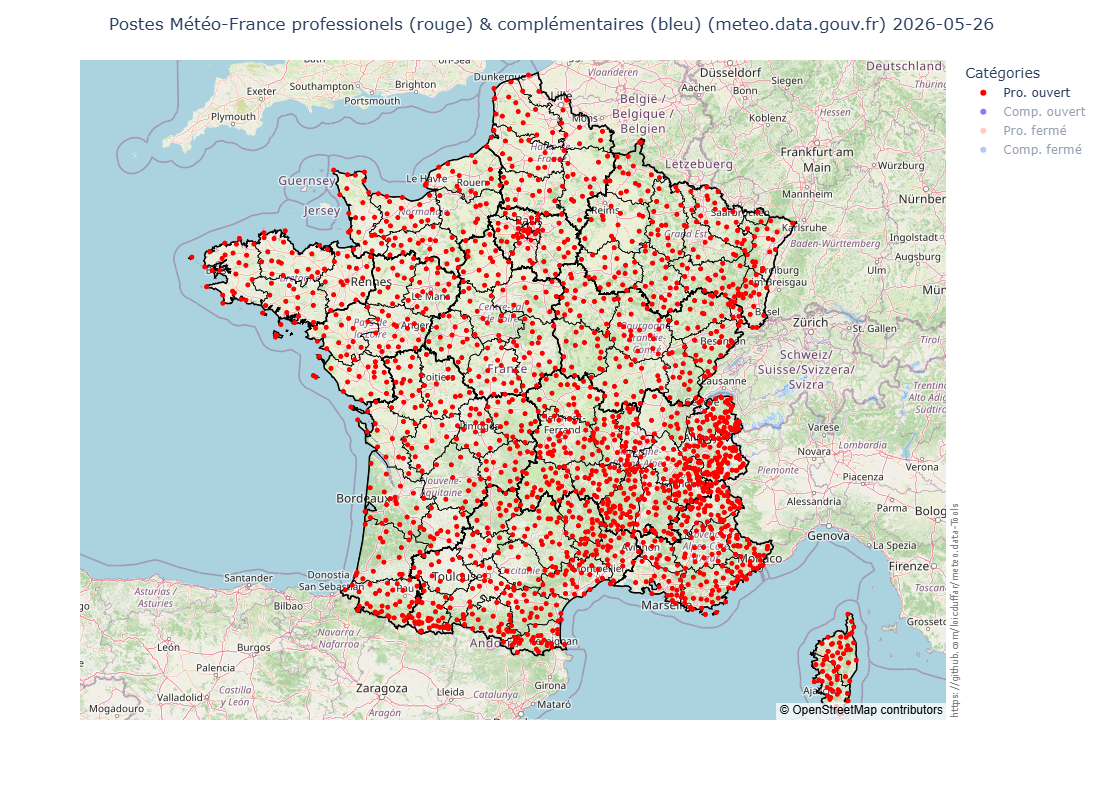

Fichiers Excel, GeoJSON et PNG sauvegardés dans le dossier :  C:\Users\<utilisateur>\Downloads


In [2]:
# trace une carte plotly des points et sauvegarde tout dans des fichier excel, html et png
import openpyxl 
import geopandas as gpd
import shapely

print(datetime.datetime.now().strftime("%Y-%m-%d %H:%M"), "Patientez 3 minutes environ (nombre élevé de postes & génération de plusieurs fichiers Excel, GeoJSON et html) ...")

def annotation():
    fig.add_annotation(text= "https://github.com/loicduffar/meteo.data-Tools", xref= "paper", yref= "paper", x= 1., y= 0, xanchor= "left", yanchor= "auto",
                   textangle= -90, showarrow= False, font= dict(size= 9, color= "gray"))

# ================ Création de la carte ====================
# première trace des postes de type 1 à 4, avec une couleur rouge ou rouge clair selon DATFERM existe ou NaT
df2= df[df['TYPE_POSTE_ACTUEL'] < 5]
fig = px.scatter_mapbox(df2, 'LAT', 'LON', hover_name= "NOM_USUEL", 
                        hover_data= ["COMMUNE", 'ALTI', 'TYPE_POSTE_ACTUEL', 'DATOUVR', 'DATFERM'],
                        color= df2['DATFERM'] == en_service , color_discrete_map= {True: 'red', False: 'lightsalmon'}, 
                        labels= {'color': 'Catégories'}, # légende de traces
                        category_orders={'color': [True, False]},  # Définir l'ordre des catégories de couleur dans la légende (important pour l'activation des traces dans la légende)
                        zoom=5, height= 800, width= 1200,
                         
            )

# ajoute une trace pour les postes de type 5, en bleu foncé ou clair selon DATFERM existe ou NaT
df2= df[df['TYPE_POSTE_ACTUEL'] == 5]
fig2= px.scatter_mapbox(df2, 'LAT', 'LON', hover_name= "NOM_USUEL",
                                hover_data= ["COMMUNE", 'ALTI', 'TYPE_POSTE_ACTUEL', 'DATOUVR', 'DATFERM'],
                                color= df2['DATFERM'] == en_service, color_discrete_map= {True: 'blue', False: 'cornflowerblue'},                              
                                labels= {'color': 'Catégories'}, # légende de traces 
                                category_orders={'color': [True, False]},  # Définir l'ordre des catégories de couleur dans la légende 
                                # zoom=5, height= 800, width= 1000, 
                                # ).data[:2] # récupère les données de la trace pour les ajouter à la carte
            )
# Ajoute 2 traces à l'aide de add_trace() qui peut ajouter une seule trace à la fois alors que scatter_mapbox() en ajoute 2  dans ce cas
fig.add_trace(fig2.data[0]) # ajoute la 1ère trace des postes de type 5 à la carte 
fig.add_trace(fig2.data[1]) # ajoute la 2ème trace des postes de type 5 à la carte

# Mise à jour des noms des traces (Attention l'ordre n'est pas intuitif, il a fallu tester pour trouver le bon)
fig.data[0].name = 'Pro. ouvert'
fig.data[1].name = 'Pro. fermé'
fig.data[2].name = 'Comp. ouvert'
fig.data[3].name = 'Comp. fermé'

title= 'Postes Météo-France professionels (rouge) & complémentaires (bleu) (meteo.data.gouv.fr) ' + datetime.datetime.now().strftime("%Y-%m-%d")
fig.update_layout(mapbox_style= "open-street-map", mapbox_zoom=5, mapbox_center = {"lat": 46.5, "lon": 2.},
                title_text= title, title_x=0.5  , 
                hoverlabel= dict(bgcolor= 'rgb(255,255,255, 0.7)'), 
                )
fig.update_traces(hoverlabel= dict(bgcolor= 'rgb(255,255,255, 0.7)'),)# couleur de fond de la légende

# Mise à jour des traces pour n'activer que la première trace tout en laissant les 3 suivantes dans la légende
fig.update_traces(visible= True, showlegend= True) 
 # désactive les 3 traces suivante
fig.update_traces(visible= 'legendonly', selector= dict(type= 'scattermapbox', name= 'Pro. fermé'))
fig.update_traces(visible= 'legendonly', selector= dict(type= 'scattermapbox', name= 'Comp. ouvert'))
fig.update_traces(visible= 'legendonly', selector= dict(type= 'scattermapbox', name= 'Comp. fermé'))
annotation()

#===================== Ajoute les couches des départements et régions françaises à partir de fichier GeoJSON en ligne
url_departements= 'https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/departements.geojson'
url_departements= "https://france-geojson.gregoiredavid.fr/repo/departements.geojson"
url_regions= "https://france-geojson.gregoiredavid.fr/repo/regions.geojson"
# charge le fichier en ligne 
geojson_departements= requests.get(url_departements).json()
geojson_regions= requests.get(url_regions).json()

fig.update_layout(mapbox_layers=[
    {
        "below": 'traces',
        "sourcetype": "geojson",
        "source": geojson_departements,
        "type": "line",
        "line": {"width": 0.7},
        "color": "black"
    },
    {
        "below": 'traces',
        "sourcetype": "geojson",
        "source": geojson_regions,
        "type": "line",
        "line": {"width": 1.5},
        "color": "black"
    }
    ])

#===================== sauvegarde les fichiers
file_start= 'postes meteo-france'
file_map= file_start + ' - carte_' + now.strftime("%Y-%m-%d")

#.......................... Fichier de la carte 
fig.write_html(os.path.join(folder_out, file_map + '.html'))
file_png= os.path.join(folder_out, file_map + '.png')
# fig.write_image(file_png) # LA GENERATION DE L IMAGE CAUSE UNE EXECUTION INFINIE ,

#.......................... Fichier GeoJSON (format standard réutilisable partout, notamment dans QGIS)
geometry = [shapely.geometry.Point(lon, lat) for lon, lat in zip(df['LON'], df['LAT'])]
gdf= gpd.GeoDataFrame(df, geometry= geometry)
gdf.to_file(os.path.join(folder_out, file_map + ".geojson"), driver='GeoJSON') #  provoque un warning de dépréciation 'pandas.Int64Index is deprecated', inévitable dans la version installée de geopandas

#.......................... Fikchier Excel par fusion des 3 fichiers TEXTE + ajout de l'image de la carte, du code geoJSON et de l'url du geoJSON hébergé sur GitHub
file_excel= os.path.join(folder_out, file_start + ' - liste_' + now.strftime("%Y-%m-%d") + '.xlsx')

onglet_liste= 'liste'
#---------- sauvegarde le dataframe dans un fichier excel sur la 2ème ligne
df.to_excel(file_excel, sheet_name= onglet_liste, startrow= 1) # df.to_excel(file_excel, index=False, sheet_name= onglet_liste)
# récupère le classeur existant pour ajouter les informations supplémentaires
wb = openpyxl.load_workbook(file_excel) # Chargement du classeur existant
ws = wb[onglet_liste] # récupère onglet_liste
# bloque la première ligne pour la figer lors du défilement
ws.freeze_panes = ws['A3']
# ajoute un titre
ws['A1']= "Liste des postes Météo-France professionnels et complémentaires en activité et fermés"
#---------- Ajout du fichier png à condition qu'il existe
if os.path.exists(file_png):
    ws.add_image(openpyxl.drawing.image.Image(file_png), 'J3') # ajoute l'image png de la carte
#---------- ajoute l'url de la version geojson hébergée sur GitHub
ws['N1']= 'Version geoJSON des poste ouverts, professionnels uniquement'
ws['P2']= 'Version geoJSON de tous les postes'
ws['T1']= 'https://github.com/loicduffar/meteo.data-Tools/blob/main/out/postes%20meteo-france%20en%20activit%C3%A9-%20carte_2024-01-13.geojson' # ancienne carte des poste en activité basée sur le fichier json de Météo-France
ws['T2']= 'https://github.com/loicduffar/meteo.data-Tools/blob/main/out/postes%20meteo-france%20-%20carte_2025-03-08.geojson'

#---------- Ajoute un nouvel au fichier excel, avec la version geojson
onglet_json= 'JSON'
ws = wb.create_sheet(onglet_json) # Création d'une nouvelle feuille
data_json= gdf.to_json()
formatted_json = json.dumps(json.loads(data_json), indent=4)  # Formater le JSON avec des indentations
for i, line in enumerate(formatted_json.split('\n'), start=1): # Ajout de la chaîne ligne par ligne à la nouvelle feuille
    ws[f'A{i}'] = line

#---------- Ajoute un nouvel onglet avec le descriptif des champs
onglet_descriptif= 'Descriptif'
ws = wb.create_sheet(onglet_descriptif) # Création d'une nouvelle feuille
for i, line in enumerate(descriptif.split('\n'), start=1): # Ajout de la chaîne ligne par ligne à la nouvelle feuille
    ws[f'A{i}'] = line

wb.save(file_excel) # Sauvegarde du classeur
fig.show()

print('Fichiers Excel, GeoJSON et PNG sauvegardés dans le dossier : ', folder_out)

In [3]:
# interroge les poste d'un département donné
departement= '21'

# rendre éditable la table
# df[df.index.str.startswith(departement)].hvplot.table(width=1400, height= 800, editable= True)
df[df.index.str.startswith(departement)]

,NOM_USUEL,COMMUNE,LIEU_DIT,DATOUVR,DATFERM,LAT,LON,LAMBX,LAMBY,ALTI,TYPE_POSTE_ACTUEL,DECALAGE,url_metadata
NUM_POSTE,,,,,,,,,,,,,
21008001,ALISE-SAINTE-REINE,ALISE-SAINTE-REINE,AGGLOMERATION,1855-01-01,1862-12-31,47.536667,4.488333,7619.0,22841.0,350,4,0,https://donneespubliques.meteofrance.fr/metado...
21009001,ALLEREY HUILLY,ALLEREY,HUILLY,1881-01-01,1909-12-31,47.188333,4.438333,7592.0,22453.0,410,4,0,https://donneespubliques.meteofrance.fr/metado...
21010001,ALOXE CORTON,ALOXE-CORTON,LES-GREVES / Cuverie du Château Corton,1954-11-01,2017-12-31,47.069000,4.861500,7917.0,22330.0,273,4,0,https://donneespubliques.meteofrance.fr/metado...
21012001,AMPILLY LE SEC,AMPILLY-LE-SEC,RN80,1863-01-01,2021-06-01,47.808333,4.529000,7642.0,23144.0,277,4,0,https://donneespubliques.meteofrance.fr/metado...
21016001,ARCEAU HAMEAU D'ARCELOT,ARCEAU,HAMEAU D'ARCELOT,1937-01-01,1945-01-31,47.385000,5.190000,8154.0,22689.0,230,4,0,https://donneespubliques.meteofrance.fr/metado...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
21711001,VIX,VIX,ROUTE-DE-POTHIERES,1861-01-01,2001-01-31,47.908333,4.540000,7647.0,23255.0,205,4,0,https://donneespubliques.meteofrance.fr/metado...
21711002,VIX BAUDY INSTITUTEUR,VIX,BAUDY INSTITUTEUR,1854-05-01,1880-12-31,47.908333,4.541667,7648.0,23255.0,200,4,0,https://donneespubliques.meteofrance.fr/metado...
21712001,VOLNAY MARIE,VOLNAY,MARIE,1855-01-01,1858-12-31,47.003333,4.781667,7859.0,22255.0,294,4,0,https://donneespubliques.meteofrance.fr/metado...
